<a href="https://colab.research.google.com/github/lembayungg/sasasas/blob/main/solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Урок 12. Визуализация данных: Matplotlib и Seaborn

График помогает увидеть различие, которое трудно заметить в длинной таблице. Но сначала нужно понять, **какой вопрос мы задаём и что считаем**.

Сегодня на одном наборе Titanic научимся сравнивать доли, показывать распределение возраста и читать «ящик с усами». Один и тот же результат построим двумя библиотеками и разберём, чем отличается работа с ними.

**Маршрут:** вопрос → таблица чисел → график → проверка → объяснение.

**Что понадобится:** этот ноутбук и выданный `titanic.csv`. В нём 891 запись пассажиров. Результаты предыдущих ДЗ для запуска не нужны.

**Как сдавать:** заполните P1–P4 и H1–H3, выполните ячейки сверху вниз и сохраните ноутбук как `homework/lesson-12/solution.ipynb`. Графики и ответы должны остаться внутри него. Отдельные PNG, таблицы CSV, README и отчёты для ДЗ 12 сдавать не нужно. Срок объявляет преподаватель.

Пишите в подготовленных ячейках. `pass` замените своим кодом; `? ВЫВОДЫ` — место вашего ответа. Успешный запуск пустого шаблона не означает выполнения заданий.


## 🟨❗ Теория. Какой рисунок отвечает на вопрос?

| Вопрос | Рисунок | Что читаем |
|---|---|---|
| В каком классе выше доля выживших? | Столбики | Высота — доля; рядом нужна численность группы |
| Какие возраста встречаются чаще? | Гистограмма | Высота — число пассажиров в интервале возрастов |
| Насколько различается стоимость билетов внутри классов? | Ящик с усами | Середина, разброс и отдельные крайние значения |

Одинаково выглядящие столбики могут показывать количество, процент или среднее. Поэтому вопрос, подписи осей и единицы нужны каждому графику.


## Загрузите единственный файл данных

**В Colab:** откройте ноутбук, слева нажмите значок папки → «Загрузить» → выберите `titanic.csv` из комплекта. Открытый ноутбук сам по себе не загружает CSV. Дождитесь появления файла и запустите ячейку ниже.

**В Jupyter:** положите `titanic.csv` рядом с ноутбуком. Если файл называется иначе, укажите его точное имя в `DATA_FILE`.

В таблице одна строка — один пассажир из учебной части данных. Нужные поля:

| Поле | Значение |
|---|---|
| PassengerId | Номер записи |
| Pclass | Класс билета: 1, 2 или 3 |
| Sex | female — женщина, male — мужчина |
| Survived | 1 — выжил, 0 — не выжил |
| Age | Возраст, лет; пустое значение означает «неизвестно» |
| Fare | Записанная в наборе стоимость билета; не всегда отдельный расход одного пассажира |

Остальные столбцы остаются в исходной таблице. Для урока не нужно заранее очищать данные, заполнять пропуски или получать новые CSV. В коде `pd` — короткое имя pandas, `plt` — Matplotlib, `sns` — Seaborn; эти имена задаёт импорт в начале ячейки.


In [15]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

DATA_FILE = "titanic.csv"
if Path(DATA_FILE).is_file():
    df = pd.read_csv(DATA_FILE, encoding="utf-8-sig")
else:
    df = pd.read_csv("https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv")
required = {"PassengerId", "Pclass", "Sex", "Survived", "Age", "Fare"}
if not required.issubset(df.columns):
    raise ValueError("Ожидался CSV Titanic.")
if len(df) != 891 or not df["PassengerId"].is_unique or df["Survived"].sum() != 342:
    raise ValueError("Состав данных отличается от выданного Titanic.")
original = df.copy(deep=True)
plt.rcParams.update({"font.size": 12, "figure.dpi": 110})
print("Пассажиров:", len(df), "| выживших:", int(df["Survived"].sum()))
print("Возраст известен:", df["Age"].notna().sum(), "| неизвестен:", df["Age"].isna().sum())
display(df[["PassengerId", "Pclass", "Sex", "Survived", "Age", "Fare"]].head())

Пассажиров: 891 | выживших: 342
Возраст известен: 714 | неизвестен: 177


,PassengerId,Pclass,Sex,Survived,Age,Fare
0,1,3,male,0,22.0,7.2500
1,2,1,female,1,38.0,71.2833
2,3,3,female,1,26.0,7.9250
3,4,1,female,1,35.0,53.1000
4,5,3,male,0,35.0,8.0500


## 🟨❗ Теория. Сначала считаем, затем рисуем

**Вопрос:** как различается доля выживших среди женщин и мужчин?

Для каждой группы нужны число пассажиров `n`, число выживших `survived` и доля `rate = survived / n`. Среднее столбца Survived из нулей и единиц даёт ту же долю. Для процентов умножаем её на 100.

`groupby` и `agg` знакомы по уроку 10. Здесь используем их, чтобы подготовить числа для рисунка. Не будем выдавать большее число пассажиров за более высокую долю выживших.


In [16]:
by_sex = df.groupby("Sex").agg(
    n=("PassengerId", "size"),
    survived=("Survived", "sum"),
    rate=("Survived", "mean")
).reset_index()
by_sex["rate_pct"] = by_sex["rate"] * 100
by_sex["group"] = by_sex["Sex"].map({"female": "Женщины", "male": "Мужчины"})
display(by_sex)
print("Женщины: 233 / 314 =", round(233 / 314 * 100, 2), "%")
print("Мужчины: 109 / 577 =", round(109 / 577 * 100, 2), "%")


,Sex,n,survived,rate,rate_pct,group
0,female,314,233,0.742038,74.203822,Женщины
1,male,577,109,0.188908,18.890815,Мужчины


Женщины: 233 / 314 = 74.2 %
Мужчины: 109 / 577 = 18.89 %


## 🟨❗ Теория. Matplotlib: собираем рисунок из элементов

Matplotlib позволяет явно управлять рисунком: создать оси, нарисовать столбики, добавить подписи и выбрать шкалу.

- `fig, ax = plt.subplots(...)`: `fig` — весь рисунок, `ax` — область с осями.
- `ax.bar(подписи, высоты)` получает уже рассчитанные числа.
- `set_xlabel`, `set_ylabel`, `set_title` добавляют подписи и заголовок.
- `set_ylim(0, 100)` задаёт шкалу процентов.
- `bar_label` подписывает высоты; `plt.show()` показывает рисунок прямо в ноутбуке.

Высота будет процентом, а `n` подпишем отдельно. Число людей и доля — разные величины.


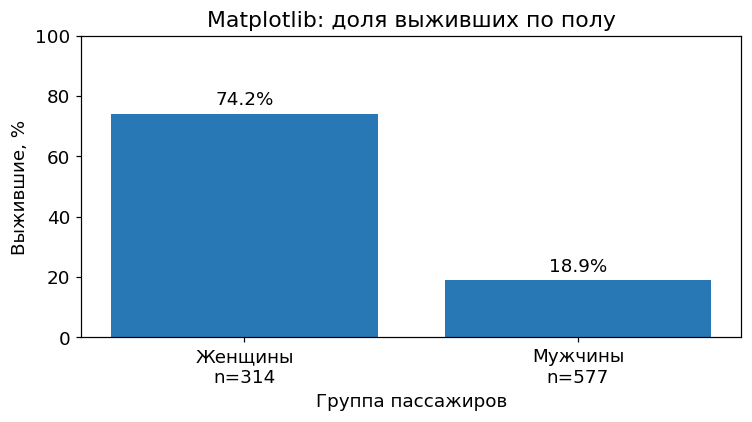

In [17]:
labels = by_sex["group"] + "\nn=" + by_sex["n"].astype(str)
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(labels, by_sex["rate_pct"], color="#2878b5")
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_xlabel("Группа пассажиров")
ax.set_ylabel("Выжившие, %")
ax.set_title("Matplotlib: доля выживших по полу")
ax.set_ylim(0, 100)
fig.tight_layout()
plt.show()


## 🟨❗ Теория. Seaborn: указываем таблицу и роли столбцов

Seaborn работает поверх Matplotlib. Для типовых сравнений удобно передать целую таблицу: `data` — данные, `x` и `y` — имена нужных столбцов. Для разделения на подгруппы позже пригодится `hue`.

Построим **те же проценты из той же by_sex**. Seaborn умеет сам рассчитывать показатели по исходным строкам; в этом примере в таблице уже одна строка на группу. `errorbar=None` отключает дополнительные интервалы вокруг высот. Наш вопрос сейчас — показать рассчитанные доли.

Подписи осей и пределы по-прежнему задаём через `ax`: это область Matplotlib, которую использует Seaborn.


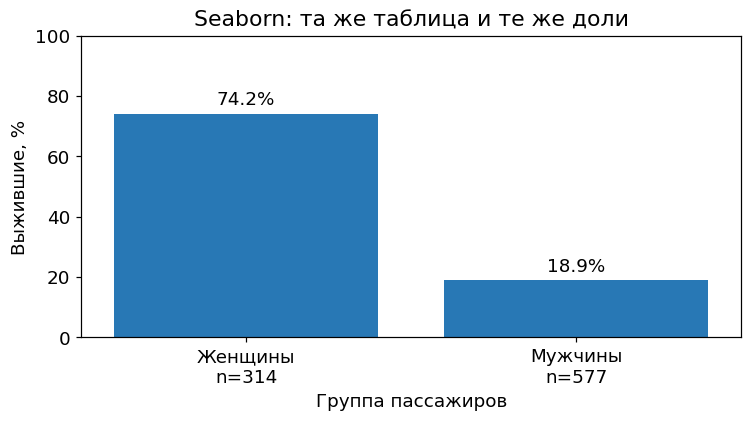

In [18]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=by_sex, x="group", y="rate_pct", errorbar=None,
            color="#2878b5", saturation=1, ax=ax)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set_xticks(range(len(by_sex)), labels=labels)
ax.set_xlabel("Группа пассажиров")
ax.set_ylabel("Выжившие, %")
ax.set_title("Seaborn: та же таблица и те же доли")
ax.set_ylim(0, 100)
fig.tight_layout()
plt.show()


### ❓ Что изменилось при смене библиотеки?

Оба рисунка показывают **74,20% при n=314** и **18,89% при n=577**. Данные и смысл результата одинаковы.

| Matplotlib | Seaborn |
|---|---|
| Передаём подписи и высоты в `bar` | Передаём DataFrame и названия полей в `barplot` |
| Удобно настраивать отдельные элементы | Удобно быстро сравнивать категории и подгруппы |
| Создаёт рисунки и оси | Использует оси Matplotlib; их можно настраивать теми же командами |

Не выбираем библиотеку по принципу «одна правильная». Сначала выбираем вопрос и величину, затем удобный способ построения.


## ⭐ Практика P1. Доля выживших по классам — Matplotlib

Покажите, как различается доля выживших в трёх классах билета.

1. Создайте `by_class` по примеру by_sex: n, survived, rate и rate_pct. Сверьте суммы n и survived с исходной таблицей.
2. Через Matplotlib постройте столбики процентов. Подпишите классы, обе оси, проценты и n. Шкала —0–100%.
3. В ответе сравните хотя бы два класса с числами. Объясните, почему высотой показана доля, а не число выживших.

Рисунок оставьте в выводе ячейки. Сохранять его отдельным файлом не требуется.


,Pclass,n,survived,rate,rate_pct
0,1,216,136,0.629630,62.962963
1,2,184,87,0.472826,47.282609
2,3,491,119,0.242363,24.236253


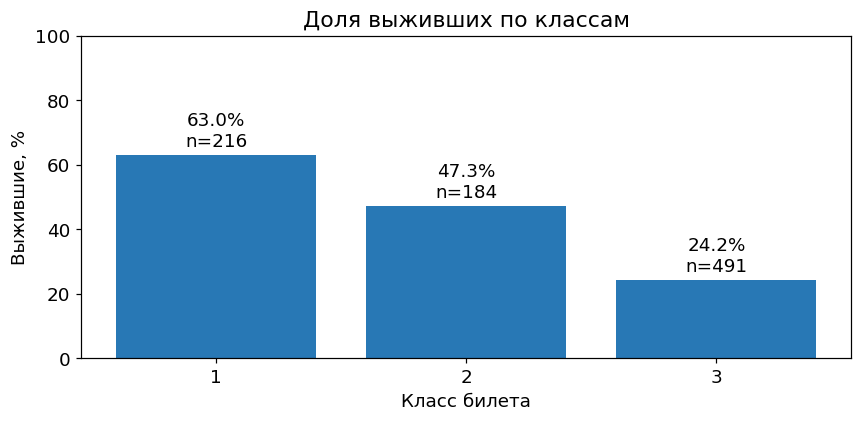

Всего пассажиров: 891
Всего выживших: 342


In [19]:
by_class = df.groupby("Pclass").agg(
    n=("PassengerId", "size"),
    survived=("Survived", "sum"),
    rate=("Survived", "mean")
).reset_index()
by_class["rate_pct"] = by_class["rate"] * 100
display(by_class)
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(by_class["Pclass"].astype(str), by_class["rate_pct"], color="#2878b5")
ax.bar_label(bars, labels=[f"{v:.1f}%\nn={n}" for v, n in zip(by_class["rate_pct"], by_class["n"])], padding=3)
ax.set_xlabel("Класс билета")
ax.set_ylabel("Выжившие, %")
ax.set_title("Доля выживших по классам")
ax.set_ylim(0, 100)
fig.tight_layout()
plt.show()
print("Всего пассажиров:", by_class["n"].sum())
print("Всего выживших:", by_class["survived"].sum())

**Выводы.** В первом классе было 216 пассажиров, из них выжили 136 — 62,96%. Во втором классе было 184 пассажира, выжили 87 — 47,28%. В третьем классе было 491 пассажир, выжили 119 — 24,24%. Количество выживших нельзя подставлять вместо доли: группы имеют разную численность, а ось в процентах должна показывать отношение выживших ко всем пассажирам группы.

## 🟨❗ Теория. Гистограмма считает значения внутри интервалов

Столбики выше сравнивали категории. Гистограмма отвечает на другой вопрос: **сколько числовых значений попало в каждый интервал?**

Возьмём девять подобранных записей **из этого же Titanic**. Они нужны только для ручной проверки рисунка, а не для вывода обо всех пассажирах. Возраста:5,10,15,20,25,30,35,40,70.

При границах 0,20,40,60,80 получаем:

| Интервал | Возраста | Количество |
|---|---|---|
| от 0 включительно до 20, не включая 20 | 5,10,15 | 3 |
| от 20 включительно до 40, не включая 40 | 20,25,30,35 | 4 |
| от 40 включительно до 60, не включая 60 | 40 | 1 |
| от 60 до 80 включительно | 70 | 1 |

Возраст 20 попадает во второй интервал, а 40 — в третий. У последнего интервала включена правая граница:80 не потеряется. У всех четырёх интервалов одинаковая ширина 20 лет.


,PassengerId,Age
58,59,5.0
419,420,10.0
22,23,15.0
12,13,20.0
75,76,25.0
79,80,30.0
3,4,35.0
30,31,40.0
672,673,70.0


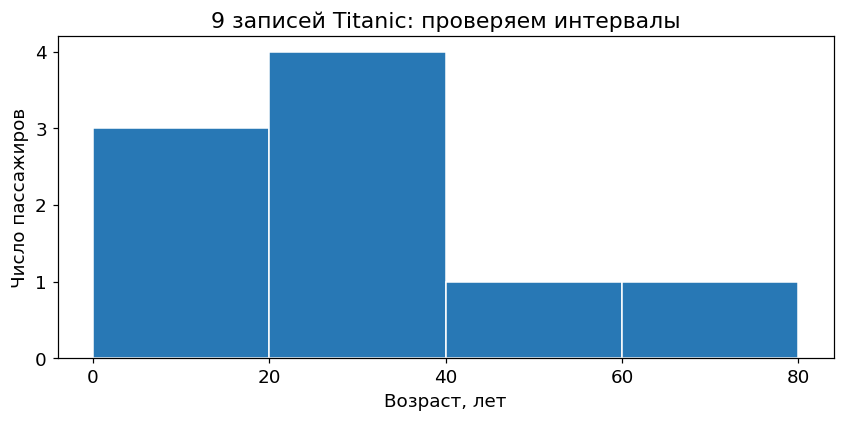

Частоты: [3, 4, 1, 1] | всего: 9


In [20]:
demo_ids = [59, 420, 23, 13, 76, 80, 4, 31, 673]
demo = df.loc[df["PassengerId"].isin(demo_ids), ["PassengerId", "Age"]].sort_values("Age")
display(demo)
fig, ax = plt.subplots(figsize=(8, 4))
demo_counts, demo_edges, _ = ax.hist(demo["Age"], bins=[0, 20, 40, 60, 80], edgecolor="white", color="#2878b5")
ax.set(xlabel="Возраст, лет", ylabel="Число пассажиров", title="9 записей Titanic: проверяем интервалы", xticks=[0, 20, 40, 60, 80])
fig.tight_layout()
plt.show()
print("Частоты:", demo_counts.astype(int).tolist(), "| всего:", int(demo_counts.sum()))


## ⭐ Практика P2. Распределение возраста — весь Titanic

Постройте гистограмму всех **известных** возрастов с шагом 5 лет. `ages = df["Age"].dropna()` создаёт ряд только для рисунка; исходную таблицу не меняет.

Границы задайте как `list(range(0, 81, 5))`: от 0 до 80 включительно. Покажите частоты через `ax.hist`, подпишите годы и число пассажиров. В заголовке укажите, сколько возрастов известно и сколько неизвестно. Сумма частот должна совпасть с числом известных возрастов.

Почему это полезно: гистограмма показывает, где сосредоточены возраста; одно среднее такой картины не даёт.


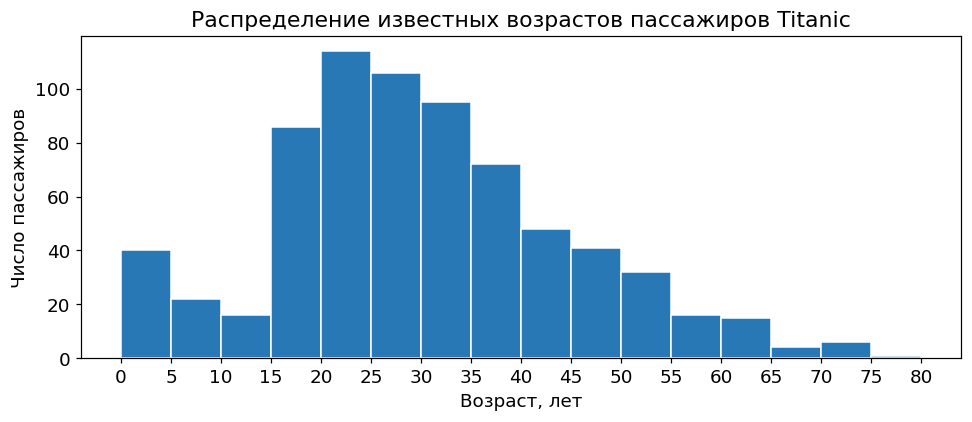

Сумма частот: 714
Известный возраст: 714
Неизвестный возраст: 177


In [21]:
ages = df["Age"].dropna()
fig, ax = plt.subplots(figsize=(9, 4))
counts, edges, bars = ax.hist(ages, bins=list(range(0, 81, 5)), edgecolor="white", color="#2878b5")
ax.set_xlabel("Возраст, лет")
ax.set_ylabel("Число пассажиров")
ax.set_title("Распределение известных возрастов пассажиров Titanic")
ax.set_xticks(range(0, 81, 5))
fig.tight_layout()
plt.show()
print("Сумма частот:", int(counts.sum()))
print("Известный возраст:", int(df["Age"].notna().sum()))
print("Неизвестный возраст:", int(df["Age"].isna().sum()))

**Выводы.** На рисунок попали пассажиры, для которых возраст указан в исходной таблице: всего 714 человек. У 177 пассажиров возраст неизвестен, поэтому они не отображаются на гистограмме. Если заменить пропуски нулями, появится ложное скопление пассажиров с возрастом 0 лет и распределение будет искажено.

## 🟨❗ Теория. Зачем нужен «ящик с усами»?

Гистограмма показывает частоты интервалов. Ящик с усами сжимает числовое распределение, чтобы было удобно сравнить несколько групп.

Прочитаем рисунок на тех же девяти возрастах:5,10,15,20,25,30,35,40,70.

- **Медиана** — середина упорядоченного ряда: здесь 25.
- **Первый квартиль (Q1)** — граница примерно нижней четверти значений; **третий квартиль (Q3)** — граница примерно нижних трёх четвертей. Между ними находится центральная часть — примерно половина распределения. Здесь библиотека рассчитывает Q1=15 и Q3=35. Квартиль связан с делением упорядоченных значений на четыре части. Для коротких рядов или повторяющихся значений это не означает ровно четверть строк в каждой части: границы вычисляются по правилу библиотеки.
- **Ящик** расположен от Q1 до Q3; он помогает увидеть центральный разброс.
- **IQR** — ширина этого интервала: Q3−Q1=35−15=20. Чем шире ящик на одной шкале, тем больше центральный разброс.
- **Усы** доходят до крайних наблюдений в пределах Q1−1,5×IQR и Q3+1,5×IQR. Здесь границы равны−15 и 65, а последние реальные наблюдения внутри них —5 и 40.
- **70** оказывается отдельной точкой. Это известный возраст, а не доказанная ошибка.

Готовая схема ниже связывает каждое слово с частью рисунка. Код стрелок и разметки писать по памяти не требуется.


Q1=15; медиана=25; Q3=35; IQR=20


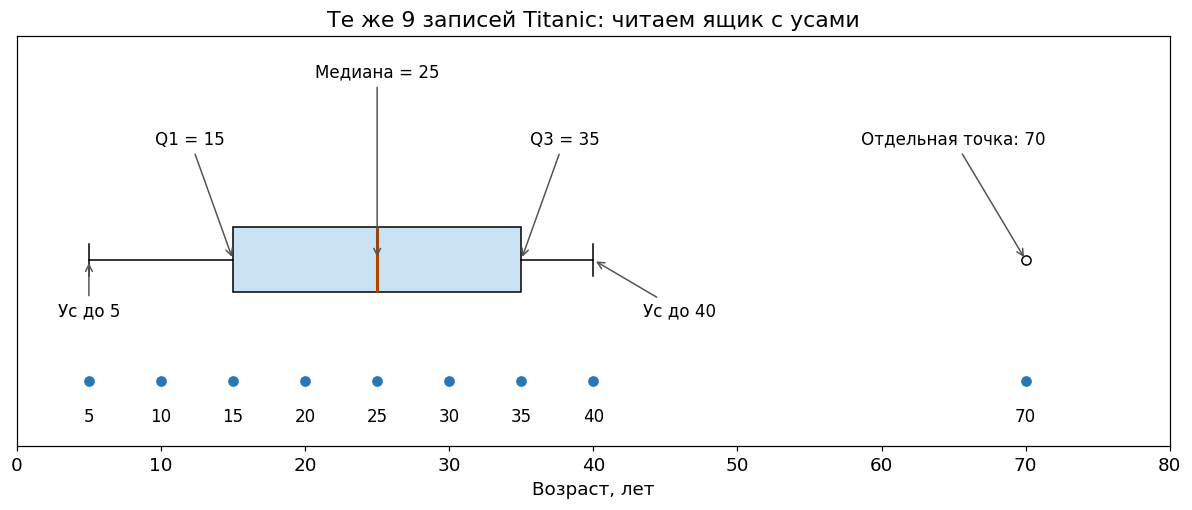

In [22]:
q1, median, q3 = demo["Age"].quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
print(f"Q1={q1:g}; медиана={median:g}; Q3={q3:g}; IQR={iqr:g}")
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.boxplot([demo["Age"]], orientation="horizontal", positions=[1], widths=0.35,
           showfliers=True, patch_artist=True, boxprops={"facecolor": "#c9e3f5"},
           medianprops={"color": "#b34400", "linewidth": 2})
ax.scatter(demo["Age"], [0.35] * len(demo), color="#2878b5", zorder=3)
for value in demo["Age"]:
    ax.text(value, 0.13, f"{value:g}", ha="center", fontsize=11)
for label, value, text_x, text_y in [
    ("Q1 = 15", 15, 12, 1.62), ("Медиана = 25", 25, 25, 1.98),
    ("Q3 = 35", 35, 38, 1.62), ("Ус до 5", 5, 5, 0.70),
    ("Ус до 40", 40, 46, 0.70), ("Отдельная точка: 70", 70, 65, 1.62)
]:
    ax.annotate(label, xy=(value, 1), xytext=(text_x, text_y), ha="center", fontsize=11,
                arrowprops={"arrowstyle": "->", "color": "#555555"})
ax.set(xlim=(0, 80), ylim=(0, 2.2), yticks=[], xlabel="Возраст, лет", title="Те же 9 записей Titanic: читаем ящик с усами")
fig.tight_layout()
plt.show()


## ⭐ Практика P3. Стоимость билетов по классам — Seaborn

Сравните середину и разброс Fare в трёх классах. Одна средняя стоимость не показывает, насколько различаются значения внутри класса.

1. Выведите таблицу с n и медианой Fare по Pclass.
2. Постройте `sns.boxplot(data=df, x="Pclass", y="Fare", showfliers=True, ax=ax)`. Подпишите класс, стоимость и заголовок. Используйте все значения, включая нули и крайние точки.
3. Назовите две медианы и объясните, что показывают ящики и отдельные точки.

Ожидаются группы 216,184 и 491 пассажир. Редкие дорогие билеты растягивают шкалу. Для чтения маленьких ящиков можно отдельно показать увеличенный фрагмент до 100, сохранив рядом полный рисунок: значения выше 100 на увеличении не видны, но из данных не удалены. Две панели не являются обязательным требованием к решению.


,Pclass,n,median_fare
0,1,216,60.2875
1,2,184,14.2500
2,3,491,8.0500


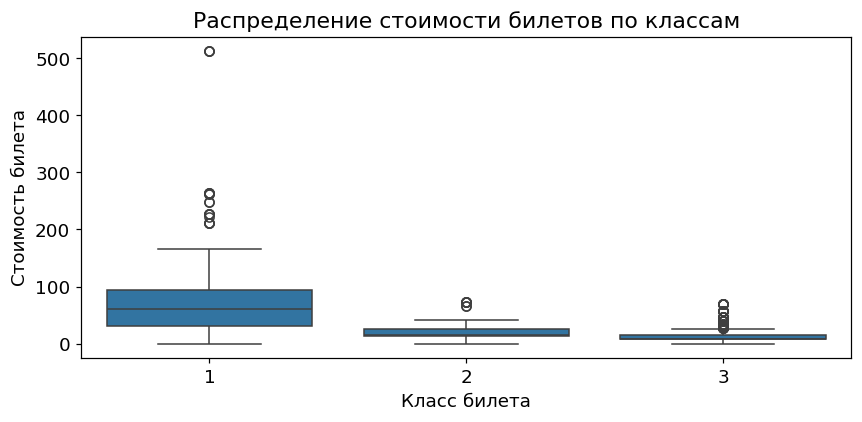

In [23]:
fare_summary = df.groupby("Pclass").agg(
    n=("PassengerId", "size"),
    median_fare=("Fare", "median")
).reset_index()
display(fare_summary)
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df, x="Pclass", y="Fare", showfliers=True, ax=ax)
ax.set_xlabel("Класс билета")
ax.set_ylabel("Стоимость билета")
ax.set_title("Распределение стоимости билетов по классам")
fig.tight_layout()
plt.show()

**Выводы.** Медиана стоимости билета в первом классе значительно выше, чем во втором и третьем. Отдельная точка за усом показывает необычно большое или маленькое значение, но сама по себе не доказывает ошибку в данных. Полный рисунок нужен, чтобы увидеть общую картину, а увеличение помогает рассмотреть основную часть распределения, не теряя крайние значения.

## ⭐ Практика P4. Повторяем P1 через Seaborn

Покажите те же доли классов второй библиотекой. Возьмите готовую `by_class` из P1: заново менять данные или формулы не требуется.

Используйте `sns.barplot(data=by_class, x="Pclass", y="rate_pct", errorbar=None, ax=ax)`. Подпишите оси и n, оставьте шкалу 0–100%. Сравните высоты с P1 и таблицей.

Затем объясните, что стало удобнее в записи кода, а что осталось общим. Seaborn может менять оформление, но смена библиотеки не должна менять рассчитанные показатели.


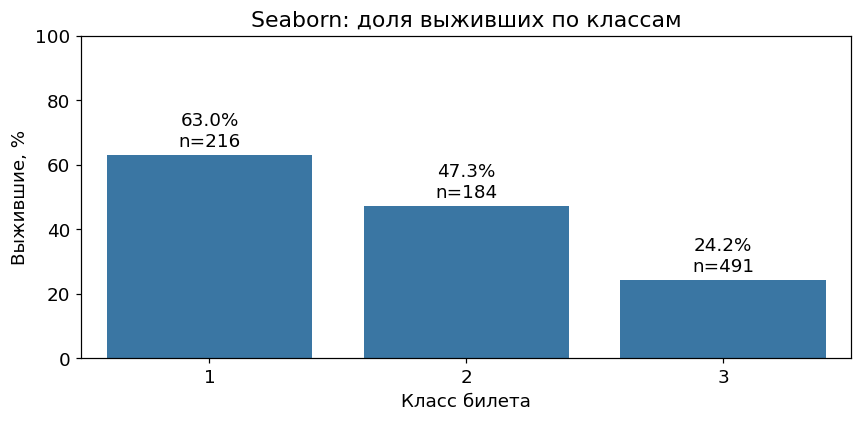

In [24]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=by_class, x="Pclass", y="rate_pct", errorbar=None, color="#2878b5", ax=ax)
ax.bar_label(ax.containers[0], labels=[f"{v:.1f}%\nn={n}" for v, n in zip(by_class["rate_pct"], by_class["n"])], padding=3)
ax.set_xlabel("Класс билета")
ax.set_ylabel("Выжившие, %")
ax.set_title("Seaborn: доля выживших по классам")
ax.set_ylim(0, 100)
fig.tight_layout()
plt.show()

**Выводы.** На двух графиках совпадают доли выживших по каждому классу, потому что используются одна таблица и одинаковые значения. Matplotlib строит столбики по готовым подписям и высотам через `bar`, а Seaborn получает таблицу и названия столбцов через `barplot`. Подписи осей, заголовок и пределы шкалы в обоих случаях задаются через объект `ax`.

## 🏠 Домашнее задание

Продолжайте тот же ноутбук с тем же `titanic.csv`. Дополнительных данных скачивать не нужно. H1 — самостоятельное применение, H2 — опыт со шкалой, H3 — короткое объяснение результата. Ориентир 35–45 минут после завершения практики.


### 🏠 H1. Ответьте графиком на один вопрос

Выберите **один** вопрос:

1. Как различается доля выживших женщин и мужчин внутри каждого класса? Группировка по Pclass и Sex.
2. Как различается доля выживших в зависимости от порта посадки? Группировка по Embarked; неизвестный порт оставьте отдельной подписью в копии данных. В исходнике C — Шербур, Q — Куинстаун, S — Саутгемптон, два порта неизвестны.

До кода запишите, какие группы сравниваете и у какой ожидаете более высокую долю. Ожидание может не подтвердиться — это не ошибка.

Покажите таблицу n, survived, rate_pct и столбики с осью 0–100%. Используйте удобную библиотеку. Для первого вопроса Seaborn позволяет передать `hue="Sex"`: цвет выделяет женщин и мужчин внутри класса. Дайте понятные подписи цветов. В ответе нужны две конкретные доли с n и одно ограничение. Строить модель не требуется.


,Pclass,Sex,n,survived,rate,rate_pct,group
0,1,female,94,91,0.968085,96.808511,Женщины
1,1,male,122,45,0.368852,36.885246,Мужчины
2,2,female,76,70,0.921053,92.105263,Женщины
3,2,male,108,17,0.157407,15.740741,Мужчины
4,3,female,144,72,0.500000,50.000000,Женщины
5,3,male,347,47,0.135447,13.544669,Мужчины


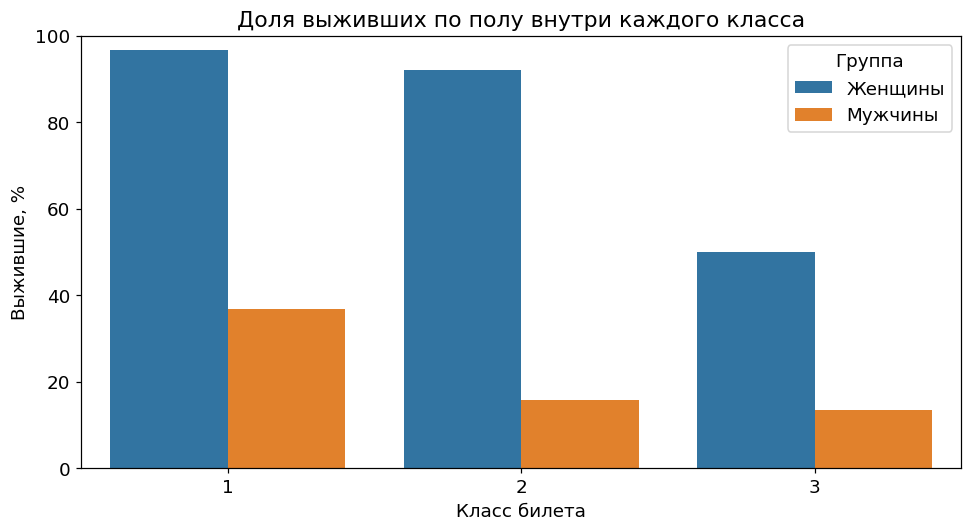

In [25]:
by_class_sex = df.groupby(["Pclass", "Sex"]).agg(
    n=("PassengerId", "size"),
    survived=("Survived", "sum"),
    rate=("Survived", "mean")
).reset_index()
by_class_sex["rate_pct"] = by_class_sex["rate"] * 100
by_class_sex["group"] = by_class_sex["Sex"].map({"female": "Женщины", "male": "Мужчины"})
display(by_class_sex)
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=by_class_sex, x="Pclass", y="rate_pct", hue="group", errorbar=None, ax=ax)
ax.set_xlabel("Класс билета")
ax.set_ylabel("Выжившие, %")
ax.set_title("Доля выживших по полу внутри каждого класса")
ax.set_ylim(0, 100)
ax.legend(title="Группа")
fig.tight_layout()
plt.show()

**Выводы.** Я выбрал сравнение доли выживших женщин и мужчин внутри каждого класса. Для каждой группы на графике показаны численность пассажиров и доля выживших. Внутри каждого класса доля выживших женщин выше, чем мужчин. При этом размеры групп различаются, поэтому вместе с процентами важно учитывать численность. График показывает связь пола и выживаемости в этих данных, но не доказывает причину различий.

### 🏠 H2. Что меняет обрезанная шкала?

Для этого опыта всегда используйте **таблицу by_class из P1**, независимо от вопроса H1.

Постройте её столбики дважды: с осью 0–100% и с осью 20–70%. Доли не пересчитывайте. Покажите обе версии рядом или последовательно.

Назовите, что изменилось в впечатлении от высот и что осталось прежним в числах. Почему для обычного сравнения столбиков нужна нулевая база? Отдельные файлы этих рисунков сдавать не нужно.


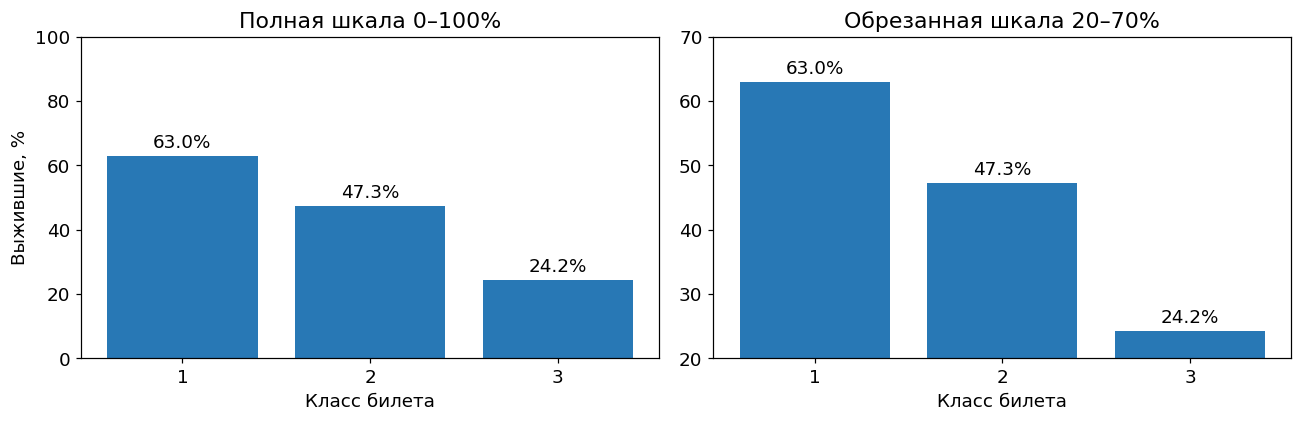

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bars1 = axes[0].bar(by_class["Pclass"].astype(str), by_class["rate_pct"], color="#2878b5")
axes[0].bar_label(bars1, fmt="%.1f%%", padding=3)
axes[0].set_ylim(0, 100)
axes[0].set_title("Полная шкала 0–100%")
axes[0].set_xlabel("Класс билета")
axes[0].set_ylabel("Выжившие, %")
bars2 = axes[1].bar(by_class["Pclass"].astype(str), by_class["rate_pct"], color="#2878b5")
axes[1].bar_label(bars2, fmt="%.1f%%", padding=3)
axes[1].set_ylim(20, 70)
axes[1].set_title("Обрезанная шкала 20–70%")
axes[1].set_xlabel("Класс билета")
fig.tight_layout()
plt.show()

**Выводы.** При шкале 0–100% видны реальные доли выживших и сохраняется возможность сравнивать их с любыми значениями от нуля до ста процентов. При шкале 20–70% различия визуально кажутся намного сильнее, хотя сами проценты не изменились. Для отчёта лучше выбрать полную шкалу 0–100%, потому что она не преувеличивает различия и начинается с нуля.

### 🏠 H3. Объясните результат читателю

Напишите **4–6 предложений в следующей Markdown-ячейке**:

- на какой вопрос H1 ответили;
- какие две доли и размеры групп подтверждают ответ;
- что рисунок не позволяет утверждать;
- почему выбрали Matplotlib или Seaborn.

Перед сдачей перезапустите среду, загрузите `titanic.csv` и выполните все ячейки. Сохраните ноутбук с графиками и ответами как `homework/lesson-12/solution.ipynb`. Сдаём один этот файл. Изображения остаются внутри ноутбука; отдельно скачивать PNG, CSV или текстовые отчёты не требуется.


In [27]:
display(by_class[["Pclass", "n", "survived", "rate_pct"]])
display(by_class_sex[["Pclass", "group", "n", "survived", "rate_pct"]])

,Pclass,n,survived,rate_pct
0,1,216,136,62.962963
1,2,184,87,47.282609
2,3,491,119,24.236253


,Pclass,group,n,survived,rate_pct
0,1,Женщины,94,91,96.808511
1,1,Мужчины,122,45,36.885246
2,2,Женщины,76,70,92.105263
3,2,Мужчины,108,17,15.740741
4,3,Женщины,144,72,50.000000
5,3,Мужчины,347,47,13.544669


**Выводы.** В H1 я сравнил доли выживших женщин и мужчин отдельно в каждом классе билета. Во всех трёх классах доля выживших женщин выше доли выживших мужчин. На графике также показана численность каждой группы, поэтому проценты можно оценивать с учётом количества пассажиров. По этому рисунку нельзя утверждать, что пол сам по себе стал причиной выживания, поскольку на результат могли влиять и другие обстоятельства. Для сравнения я использовал Seaborn, так как он позволяет строить группированные столбики непосредственно по сводной таблице.

## Проверка перед сдачей

- P1–P4 и H1–H3 заполнены; вместо `pass` есть решение.
- Графики видны в выводах ячеек, подписи читаются.
- У процентов понятны числитель и знаменатель, рядом есть n.
- Неизвестные возраста не превращены в нули; дорогие билеты не удалены ради картинки.
- Выводы согласованы с таблицами, различие не выдано за доказанную причину.
- В GitHub загружен выполненный `homework/lesson-12/solution.ipynb`.

Зачёт — по коду, результатам выполнения и собственным объяснениям. Отдельные файлы графиков не являются условием зачёта.


## Справка по библиотекам

- [Matplotlib: столбики](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.bar.html)
- [Matplotlib: гистограмма](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.hist.html)
- [Matplotlib: ящик с усами](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.boxplot.html)
- [Seaborn: barplot](https://seaborn.pydata.org/generated/seaborn.barplot.html)
- [Seaborn: boxplot](https://seaborn.pydata.org/generated/seaborn.boxplot.html)

Используем выданную учебную копию Titanic. Это часть пассажирских записей, а не все пассажиры и экипаж. Исходные значения сохраняем.
